In [1]:
import os, json, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import silhouette_score

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
if Path('/content').exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError:
        pass
DATA_PATH = Path('/content/drive/MyDrive/model_ready_category_dataset.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('/mnt/data/model_ready_category_dataset(4).csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('model_ready_category_dataset.csv')
OUTPUT_DIR = Path('/content/drive/MyDrive/model_4_cluster_based_outputs') if Path('/content/drive/MyDrive').exists() else Path('model_4_cluster_based_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CATEGORY = 'Product Category'
DATE = 'week_start'
TARGET = 'weekly_quantity'
M = 52
HORIZONS = [4, 8, 12]
ORIGINS = {'spring_2025':'2025-04-07','summer_2025':'2025-07-07','early_autumn_2025':'2025-09-08','q4_year_end_2025':'2025-10-06'}
INNER_OFFSETS = [48, 36, 24, 12]
INNER_HORIZON = 12
CLUSTER_CONFIGS = [{'algorithm':a,'k':k} for a in ['kmeans','agglomerative','gmm'] for k in [2,3,4]]
EXPERTS = ['seasonal_naive_52','moving_average_4','moving_average_12','croston','tsb','extra_trees_a','extra_trees_b']
TREE_GRID = {'extra_trees_a':{'n_estimators':200,'max_depth':8,'min_samples_leaf':3,'max_features':0.85},'extra_trees_b':{'n_estimators':300,'max_depth':14,'min_samples_leaf':2,'max_features':1.0}}
print('Input:', DATA_PATH)
print('Cluster configurations:', len(CLUSTER_CONFIGS))
print('Experts:', EXPERTS)
print('Inner origins per outer origin:', len(INNER_OFFSETS))
print('Tree hyperparameter grid:', json.dumps(TREE_GRID,indent=2))

Mounted at /content/drive
Input: /content/drive/MyDrive/model_ready_category_dataset.csv
Cluster configurations: 9
Experts: ['seasonal_naive_52', 'moving_average_4', 'moving_average_12', 'croston', 'tsb', 'extra_trees_a', 'extra_trees_b']
Inner origins per outer origin: 4
Tree hyperparameter grid: {
  "extra_trees_a": {
    "n_estimators": 200,
    "max_depth": 8,
    "min_samples_leaf": 3,
    "max_features": 0.85
  },
  "extra_trees_b": {
    "n_estimators": 300,
    "max_depth": 14,
    "min_samples_leaf": 2,
    "max_features": 1.0
  }
}


In [2]:
raw = pd.read_csv(DATA_PATH, usecols=[CATEGORY,DATE,TARGET,'transaction_count'])
raw[DATE] = pd.to_datetime(raw[DATE])
raw[CATEGORY] = raw[CATEGORY].astype(str)
raw[TARGET] = pd.to_numeric(raw[TARGET], errors='raise').clip(lower=0)
raw['transaction_count'] = pd.to_numeric(raw['transaction_count'], errors='coerce').fillna(0).clip(lower=0)
assert not raw.duplicated([CATEGORY,DATE]).any()
categories = sorted(raw[CATEGORY].unique())
weeks = pd.date_range(raw[DATE].min(),raw[DATE].max(),freq='7D')
pieces=[]
for cat in categories:
    x=raw.loc[raw[CATEGORY]==cat].set_index(DATE)[[TARGET,'transaction_count']].reindex(weeks).fillna(0)
    x[CATEGORY]=cat
    x.index.name=DATE
    pieces.append(x.reset_index())
panel=pd.concat(pieces,ignore_index=True).sort_values([CATEGORY,DATE]).reset_index(drop=True)
assert len(categories)==40 and len(weeks)==155 and len(panel)==6200
print('Panel:',panel.shape,'Categories:',len(categories),'Weeks:',len(weeks))
print('Date range:',weeks.min().date(),weeks.max().date())

Panel: (6200, 4) Categories: 40 Weeks: 155
Date range: 2023-01-09 2025-12-22


In [3]:
def seasonal_scale(y):
    y=np.asarray(y,float)
    if len(y)<=M:
        return np.nan
    z=float(np.mean(np.abs(y[M:]-y[:-M])))
    return z if np.isfinite(z) and z>1e-12 else np.nan

def metrics(y,p,history):
    y=np.asarray(y,float)
    p=np.asarray(p,float)
    e=np.abs(y-p)
    scale=seasonal_scale(history)
    denom=np.abs(y)+np.abs(p)
    return {'MAE':float(e.mean()),'RMSE':float(np.sqrt(np.mean((y-p)**2))),'MASE':float(e.mean()/scale) if np.isfinite(scale) else np.nan,'sMAPE':float(np.mean(np.divide(2*e,denom,out=np.zeros_like(e),where=denom>1e-12))*100),'MASE_scale':scale}

def demand_profiles(history):
    rows=[]
    for cat,g in history.groupby(CATEGORY,sort=True):
        y=g.sort_values(DATE)[TARGET].to_numpy(float)
        pos=y[y>0]
        idx=np.flatnonzero(y>0)
        mean=y.mean()
        std=y.std(ddof=1) if len(y)>1 else 0
        adi=float(np.diff(idx).mean()) if len(idx)>1 else float(len(y))
        rows.append({CATEGORY:cat,'mean':mean,'median':np.median(y),'std':std,'cv':std/mean if mean>0 else 0,'zero_ratio':np.mean(y==0),'adi':adi,'max':y.max(),'positive_mean':pos.mean() if len(pos) else 0,'recent_4':y[-4:].mean(),'recent_12':y[-12:].mean(),'trend':np.polyfit(np.arange(len(y)),y,1)[0]})
    return pd.DataFrame(rows)

PROFILE_COLS=['mean','median','std','cv','zero_ratio','adi','max','positive_mean','recent_4','recent_12','trend']
LOG_COLS=['mean','median','std','cv','adi','max','positive_mean','recent_4','recent_12']

def assign_clusters(history,config):
    prof=demand_profiles(history)
    x=prof[PROFILE_COLS].copy()
    for c in LOG_COLS:
        x[c]=np.sign(x[c])*np.log1p(np.abs(x[c]))
    z=StandardScaler().fit_transform(x)
    k=config['k']
    if config['algorithm']=='kmeans':
        labels=KMeans(n_clusters=k,n_init=20,random_state=SEED).fit_predict(z)
    elif config['algorithm']=='agglomerative':
        labels=AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(z)
    else:
        labels=GaussianMixture(n_components=k,random_state=SEED,reg_covar=1e-4,n_init=3).fit_predict(z)
    prof['cluster']=labels.astype(int)
    quality=float(silhouette_score(z,labels)) if len(set(labels))>1 else np.nan
    return prof,quality

In [4]:
LAGS=[1,2,4,8,12,26,52]
WINDOWS=[4,8,12,26]
EXOG_LAGS=[12,26,52]

def feature_row(date,y,exog_by_date):
    date=pd.Timestamp(date)
    w=int(date.isocalendar().week)
    r={'year':date.year,'month':date.month,'quarter':date.quarter,'week_of_year':w,'week_sin':np.sin(2*np.pi*w/52),'week_cos':np.cos(2*np.pi*w/52),'month_sin':np.sin(2*np.pi*date.month/12),'month_cos':np.cos(2*np.pi*date.month/12)}
    y=np.asarray(y,float)
    for lag in LAGS:
        r[f'lag_{lag}']=float(y[-lag]) if len(y)>=lag else 0.0
    for window in WINDOWS:
        v=y[-window:]
        r[f'rolling_mean_{window}']=float(v.mean())
        r[f'rolling_std_{window}']=float(v.std(ddof=1)) if len(v)>1 else 0.0
        r[f'zero_ratio_{window}']=float(np.mean(v==0))
    for lag in EXOG_LAGS:
        source=date-pd.Timedelta(weeks=lag)
        r[f'transaction_count_lag_{lag}']=float(exog_by_date.get(source,0))
    return r

FEATURES=list(feature_row(pd.Timestamp('2025-01-01'),np.zeros(60),{}).keys())+['category_code']
CAT_CODES={cat:i for i,cat in enumerate(categories)}

def supervised(history,cats):
    rows=[]
    for cat in sorted(cats):
        g=history.loc[history[CATEGORY]==cat].sort_values(DATE)
        y=g[TARGET].to_numpy(float)
        dates=g[DATE].tolist()
        exog=dict(zip(dates,g['transaction_count']))
        for i in range(M,len(y)):
            row=feature_row(dates[i],y[:i],exog)
            row['category_code']=CAT_CODES[cat]
            row[TARGET]=y[i]
            rows.append(row)
    return pd.DataFrame(rows)

def croston(y,h,alpha=.1):
    y=np.asarray(y,float)
    idx=np.flatnonzero(y>0)
    if not len(idx):return np.zeros(h)
    z=y[idx[0]]
    p=max(idx[0]+1,1)
    prev=idx[0]
    for j in idx[1:]:
        z+=alpha*(y[j]-z)
        p+=alpha*((j-prev)-p)
        prev=j
    return np.repeat(max(z/max(p,1e-12),0),h)

def tsb(y,h,alpha=.1,beta=.1):
    y=np.asarray(y,float)
    p=float(y[0]>0)
    z=float(y[0] if y[0]>0 else (y[y>0].mean() if (y>0).any() else 0))
    for v in y[1:]:
        p+=beta*(float(v>0)-p)
        if v>0:z+=alpha*(v-z)
    return np.repeat(max(p*z,0),h)

def forecast_expert(history,cats,dates,expert,origin,model_params=None):
    dates=pd.to_datetime(dates)
    out=[]
    model=None
    if expert in TREE_GRID:
        train=supervised(history,cats)
        if train.empty:raise ValueError('Insufficient supervised observations')
        params={**TREE_GRID[expert],'n_jobs':-1,'random_state':SEED}
        if model_params:params.update(model_params)
        model=ExtraTreesRegressor(**params)
        model.fit(train[FEATURES],train[TARGET])
    for cat in sorted(cats):
        g=history.loc[history[CATEGORY]==cat].sort_values(DATE)
        y=g[TARGET].to_numpy(float)
        exog=dict(zip(g[DATE],g['transaction_count']))
        h=len(dates)
        if expert=='seasonal_naive_52':pred=np.array([y[-M+i] for i in range(h)])
        elif expert=='moving_average_4':pred=np.repeat(y[-4:].mean(),h)
        elif expert=='moving_average_12':pred=np.repeat(y[-12:].mean(),h)
        elif expert=='croston':pred=croston(y,h)
        elif expert=='tsb':pred=tsb(y,h)
        else:
            work=y.tolist()
            pred=[]
            for d in dates:
                for lag in EXOG_LAGS:
                    assert pd.Timestamp(d)-pd.Timedelta(weeks=lag)<pd.Timestamp(origin)
                row=feature_row(d,work,exog)
                row['category_code']=CAT_CODES[cat]
                p=max(float(model.predict(pd.DataFrame([row])[FEATURES])[0]),0)
                pred.append(p)
                work.append(p)
        for d,p in zip(dates,pred):
            out.append({CATEGORY:cat,DATE:d,'y_pred':max(float(p),0)})
    return pd.DataFrame(out),model

In [5]:
def validation_origins(outer_origin):
    outer_origin=pd.Timestamp(outer_origin)
    for offset in INNER_OFFSETS:
        v=outer_origin-pd.Timedelta(weeks=offset)
        dates=pd.date_range(v,periods=12,freq='7D')
        assert dates[-1]<outer_origin
        yield v,dates

def evaluate_fold(train,actual,pred,origin_label,config_id,fold_id,expert,cluster,quality):
    merged=actual[[CATEGORY,DATE,TARGET]].merge(pred,on=[CATEGORY,DATE],how='left',validate='one_to_one')
    assert len(merged)==len(actual) and merged['y_pred'].notna().all()
    rows=[]
    for cat,g in merged.groupby(CATEGORY):
        hist=train.loc[train[CATEGORY]==cat,TARGET].to_numpy(float)
        g=g.sort_values(DATE)
        for h in HORIZONS:
            q=g.iloc[:h]
            score=metrics(q[TARGET],q['y_pred'],hist)
            rows.append({'outer_origin_label':origin_label,'config_id':config_id,'fold':fold_id,'validation_origin':g[DATE].min(),CATEGORY:cat,'cluster_at_fold':int(cluster),'expert_id':expert,'horizon_weeks':h,'silhouette':quality,**score})
    return rows

def select_cluster_expert(prior,held_categories,h):
    z=prior.loc[(prior[CATEGORY].isin(held_categories))&(prior['horizon_weeks']==h)]
    scores=z.groupby(['expert_id',CATEGORY],as_index=False)['MASE'].mean()
    ranking=scores.groupby('expert_id',as_index=False).agg(mean_MASE=('MASE','mean'),valid_categories=('MASE','count'))
    ranking=ranking.loc[ranking['valid_categories']>0].sort_values(['mean_MASE','expert_id'])
    return ranking.iloc[0]['expert_id'] if not ranking.empty else 'seasonal_naive_52'

all_validation=[]
all_config_scores=[]
selected_configs=[]
for origin_label,origin_str in ORIGINS.items():
    origin=pd.Timestamp(origin_str)
    print('Tuning:',origin_label)
    for config in CLUSTER_CONFIGS:
        config_id=f"{config['algorithm']}_k{config['k']}"
        config_rows=[]
        for fold_id,(v,dates) in enumerate(validation_origins(origin),1):
            train=panel.loc[panel[DATE]<v]
            actual=panel.loc[panel[DATE].isin(dates)]
            profiles,quality=assign_clusters(train,config)
            for cluster,cats in profiles.groupby('cluster')[CATEGORY]:
                cats=cats.tolist()
                for expert in EXPERTS:
                    pred,_=forecast_expert(train,cats,dates,expert,v)
                    config_rows.extend(evaluate_fold(train,actual.loc[actual[CATEGORY].isin(cats)],pred,origin_label,config_id,fold_id,expert,cluster,quality))
        z=pd.DataFrame(config_rows)
        all_validation.extend(config_rows)
        held=[]
        for fold in sorted(z['fold'].unique())[1:]:
            prior=z.loc[z['fold']<fold]
            target=z.loc[z['fold']==fold]
            for cluster,cats in target.groupby('cluster_at_fold')[CATEGORY]:
                cats=sorted(cats.unique())
                for h in HORIZONS:
                    expert=select_cluster_expert(prior,cats,h)
                    chosen=target.loc[(target['cluster_at_fold']==cluster)&(target['horizon_weeks']==h)&(target['expert_id']==expert)].copy()
                    assert len(chosen)==len(cats)
                    held.append(chosen)
        held=pd.concat(held,ignore_index=True)
        all_config_scores.append({'outer_origin_label':origin_label,'config_id':config_id,'algorithm':config['algorithm'],'k':config['k'],'cv_mean_MASE':held['MASE'].mean(),'cv_median_MASE':held['MASE'].median(),'cv_mean_MAE':held['MAE'].mean(),'cv_evaluations':held['MASE'].count(),'mean_silhouette':z['silhouette'].mean(),'held_folds':held['fold'].nunique()})
        print(config_id,round(float(held['MASE'].mean()),4))
        pd.DataFrame(all_validation).to_csv(OUTPUT_DIR/'model_4_inner_validation.csv',index=False)
        pd.DataFrame(all_config_scores).to_csv(OUTPUT_DIR/'model_4_cluster_tuning.csv',index=False)
    rank=pd.DataFrame([r for r in all_config_scores if r['outer_origin_label']==origin_label]).sort_values(['cv_mean_MASE','cv_mean_MAE','config_id'],na_position='last')
    best=rank.iloc[0].to_dict()
    selected_configs.append(best)
    print('Selected:',best['config_id'],'Validation MASE:',round(best['cv_mean_MASE'],4))
    pd.DataFrame(selected_configs).to_csv(OUTPUT_DIR/'model_4_selected_cluster_configs.csv',index=False)
validation_df=pd.DataFrame(all_validation)
config_df=pd.DataFrame(all_config_scores)
selected_df=pd.DataFrame(selected_configs)
display(selected_df)


Tuning: spring_2025
kmeans_k2 4.1364
kmeans_k3 4.0932
kmeans_k4 4.3232
agglomerative_k2 4.1532
agglomerative_k3 4.0938
agglomerative_k4 4.2013
gmm_k2 4.124
gmm_k3 4.176
gmm_k4 4.282
Selected: kmeans_k3 Validation MASE: 4.0932
Tuning: summer_2025
kmeans_k2 1.1181
kmeans_k3 1.8247
kmeans_k4 1.7965
agglomerative_k2 1.1815
agglomerative_k3 1.3312
agglomerative_k4 1.3585
gmm_k2 1.1682
gmm_k3 1.3279
gmm_k4 1.1821
Selected: kmeans_k2 Validation MASE: 1.1181
Tuning: early_autumn_2025
kmeans_k2 0.8264
kmeans_k3 0.8135
kmeans_k4 0.7895
agglomerative_k2 0.812
agglomerative_k3 0.8308
agglomerative_k4 0.8242
gmm_k2 0.836
gmm_k3 0.8105
gmm_k4 0.7826
Selected: gmm_k4 Validation MASE: 0.7826
Tuning: q4_year_end_2025
kmeans_k2 0.9517
kmeans_k3 0.9801
kmeans_k4 0.9274
agglomerative_k2 0.9348
agglomerative_k3 0.9832
agglomerative_k4 0.9545
gmm_k2 0.9684
gmm_k3 1.0102
gmm_k4 0.9309
Selected: kmeans_k4 Validation MASE: 0.9274


,outer_origin_label,config_id,algorithm,k,cv_mean_MASE,cv_median_MASE,cv_mean_MAE,cv_evaluations,mean_silhouette,held_folds
0,spring_2025,kmeans_k3,kmeans,3,4.093239,0.334789,56.834317,339,0.335955,3
1,summer_2025,kmeans_k2,kmeans,2,1.118065,0.503530,74.647454,348,0.368378,3
2,early_autumn_2025,gmm_k4,gmm,4,0.782593,0.424860,51.957826,351,0.309434,3
3,q4_year_end_2025,kmeans_k4,kmeans,4,0.927410,0.518778,57.728951,351,0.325478,3


In [10]:
outer_rows=[]
forecast_rows=[]
profile_rows=[]
expert_rows=[]
shap_models=[]
for origin_label,origin_str in ORIGINS.items():
    origin=pd.Timestamp(origin_str)
    train=panel.loc[panel[DATE]<origin]
    config_info=selected_df.loc[selected_df['outer_origin_label']==origin_label].iloc[0]
    config={'algorithm':config_info['algorithm'],'k':int(config_info['k'])}
    profiles,quality=assign_clusters(train,config)
    profiles['outer_origin_label']=origin_label
    profile_rows.append(profiles)
    valid=validation_df.loc[(validation_df['outer_origin_label']==origin_label)&(validation_df['config_id']==config_info['config_id'])]
    expert_score=valid
    dates=pd.date_range(origin,periods=12,freq='7D')
    for cluster,cats in profiles.groupby('cluster')[CATEGORY]:
        cats=cats.tolist()
        for h in HORIZONS:
            expert=select_cluster_expert(expert_score,cats,h)
            selected_score=expert_score.loc[(expert_score[CATEGORY].isin(cats))&(expert_score['horizon_weeks']==h)&(expert_score['expert_id']==expert),'MASE'].mean()
            expert_rows.append({'outer_origin_label':origin_label,'cluster':int(cluster),'horizon_weeks':h,'expert_id':expert,'inner_mean_MASE':selected_score,'cluster_categories':len(cats)})
            pred,model=forecast_expert(train,cats,dates[:h],expert,origin)
            if model is not None and h==12:
                shap_models.append((origin_label,int(cluster),model,train,cats))
            actual=panel.loc[(panel[DATE].isin(dates[:h]))&(panel[CATEGORY].isin(cats))]
            merged=actual[[CATEGORY,DATE,TARGET]].merge(pred,on=[CATEGORY,DATE],validate='one_to_one')
            for cat,g in merged.groupby(CATEGORY):
                hist=train.loc[train[CATEGORY]==cat,TARGET].to_numpy(float)
                score=metrics(g[TARGET],g['y_pred'],hist)
                outer_rows.append({'scenario_id':f'{origin_label}_h{h}','outer_origin_label':origin_label,'outer_origin':origin,'horizon_weeks':h,CATEGORY:cat,'cluster':int(cluster),'expert_id':expert,'selected_cluster_config':config_info['config_id'],**score})
            merged['scenario_id']=f'{origin_label}_h{h}'
            merged['outer_origin_label']=origin_label
            merged['horizon_weeks']=h
            merged['cluster']=int(cluster)
            merged['expert_id']=expert
            merged['selected_cluster_config']=config_info['config_id']
            forecast_rows.append(merged)
outer_df=pd.DataFrame(outer_rows)
forecasts_df=pd.concat(forecast_rows,ignore_index=True)
profiles_df=pd.concat(profile_rows,ignore_index=True)
expert_df=pd.DataFrame(expert_rows)
assert len(outer_df)==480
assert outer_df['MASE'].notna().sum()==468
assert len(forecasts_df)==40*4*sum(HORIZONS)
outer_df.to_csv(OUTPUT_DIR/'model_4_outer_test_results.csv',index=False)
forecasts_df.to_csv(OUTPUT_DIR/'model_4_outer_forecasts.csv',index=False)
profiles_df.to_csv(OUTPUT_DIR/'model_4_outer_cluster_profiles.csv',index=False)
expert_df.to_csv(OUTPUT_DIR/'model_4_selected_experts.csv',index=False)
scenario_summary=outer_df.groupby(['scenario_id','outer_origin_label','horizon_weeks'],as_index=False).agg(MASE=('MASE','mean'),MAE=('MAE','mean'),RMSE=('RMSE','mean'),sMAPE=('sMAPE','mean'),valid_MASE_N=('MASE','count'))
overall_summary=pd.DataFrame([{'mean_MASE':outer_df['MASE'].mean(),'mean_MAE':outer_df['MAE'].mean(),'mean_RMSE':outer_df['RMSE'].mean(),'mean_sMAPE':outer_df['sMAPE'].mean(),'valid_MASE_evaluations':outer_df['MASE'].count(),'undefined_MASE_evaluations':outer_df['MASE'].isna().sum(),'n_outer_evaluations':len(outer_df)}])
scenario_summary.to_csv(OUTPUT_DIR/'model_4_scenario_summary.csv',index=False)
overall_summary.to_csv(OUTPUT_DIR/'model_4_overall_summary.csv',index=False)
display(scenario_summary)
display(overall_summary)
display(expert_df)

,scenario_id,outer_origin_label,horizon_weeks,MASE,MAE,RMSE,sMAPE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,1.352309,74.200141,103.855187,111.689267,39
1,early_autumn_2025_h4,early_autumn_2025,4,2.623875,179.893998,198.135781,125.264427,39
2,early_autumn_2025_h8,early_autumn_2025,8,1.756580,85.575846,110.101983,108.215675,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,0.886738,45.229405,67.862968,77.986210,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,1.023947,78.110285,92.498729,81.793250,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,1.025549,60.686278,81.527207,72.103348,39
6,spring_2025_h12,spring_2025,12,1.143941,69.054167,97.156733,78.604261,39
7,spring_2025_h4,spring_2025,4,1.465469,106.691667,123.581701,97.864720,39
8,spring_2025_h8,spring_2025,8,1.235252,81.251563,103.390100,95.705586,39
9,summer_2025_h12,summer_2025,12,1.139505,56.894624,95.437496,140.945382,39


,mean_MASE,mean_MAE,mean_RMSE,mean_sMAPE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,1.225554,77.308503,98.474142,103.155654,468,12,480


,outer_origin_label,cluster,horizon_weeks,expert_id,inner_mean_MASE,cluster_categories
0,spring_2025,0,4,seasonal_naive_52,0.622553,8
1,spring_2025,0,8,seasonal_naive_52,0.625409,8
2,spring_2025,0,12,seasonal_naive_52,0.704979,8
3,spring_2025,1,4,moving_average_12,0.742846,21
4,spring_2025,1,8,moving_average_12,5.891397,21
5,spring_2025,1,12,seasonal_naive_52,7.232191,21
6,spring_2025,2,4,moving_average_4,3.253878,11
7,spring_2025,2,8,moving_average_4,2.102386,11
8,spring_2025,2,12,seasonal_naive_52,5.160201,11
9,summer_2025,0,4,moving_average_12,0.897809,16


,scenario_id,outer_origin_label,horizon_weeks,MASE,MAE,RMSE,sMAPE,valid_MASE_N
0,early_autumn_2025_h12,early_autumn_2025,12,1.352309,74.200141,103.855187,111.689267,39
1,early_autumn_2025_h4,early_autumn_2025,4,2.623875,179.893998,198.135781,125.264427,39
2,early_autumn_2025_h8,early_autumn_2025,8,1.756580,85.575846,110.101983,108.215675,39
3,q4_year_end_2025_h12,q4_year_end_2025,12,0.886738,45.229405,67.862968,77.986210,39
4,q4_year_end_2025_h4,q4_year_end_2025,4,1.023947,78.110285,92.498729,81.793250,39
5,q4_year_end_2025_h8,q4_year_end_2025,8,1.025549,60.686278,81.527207,72.103348,39
6,spring_2025_h12,spring_2025,12,1.143941,69.054167,97.156733,78.604261,39
7,spring_2025_h4,spring_2025,4,1.465469,106.691667,123.581701,97.864720,39
8,spring_2025_h8,spring_2025,8,1.235252,81.251563,103.390100,95.705586,39
9,summer_2025_h12,summer_2025,12,1.139505,56.894624,95.437496,140.945382,39


,mean_MASE,mean_MAE,mean_RMSE,mean_sMAPE,valid_MASE_evaluations,undefined_MASE_evaluations,n_outer_evaluations
0,1.225554,77.308503,98.474142,103.155654,468,12,480


,outer_origin_label,cluster,horizon_weeks,expert_id,inner_mean_MASE,cluster_categories
0,spring_2025,0,4,seasonal_naive_52,0.622553,8
1,spring_2025,0,8,seasonal_naive_52,0.625409,8
2,spring_2025,0,12,seasonal_naive_52,0.704979,8
3,spring_2025,1,4,moving_average_12,0.742846,21
4,spring_2025,1,8,moving_average_12,5.891397,21
5,spring_2025,1,12,seasonal_naive_52,7.232191,21
6,spring_2025,2,4,moving_average_4,3.253878,11
7,spring_2025,2,8,moving_average_4,2.102386,11
8,spring_2025,2,12,seasonal_naive_52,5.160201,11
9,summer_2025,0,4,moving_average_12,0.897809,16


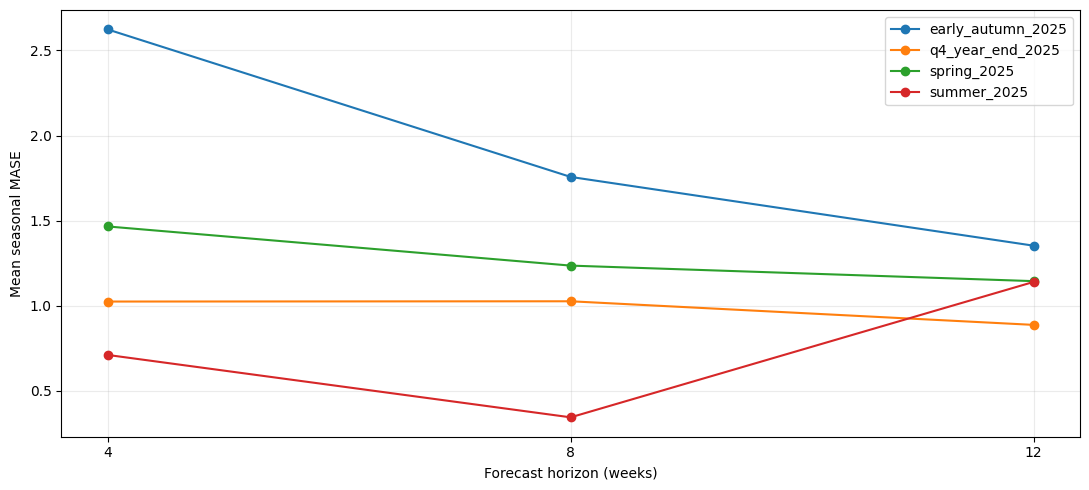

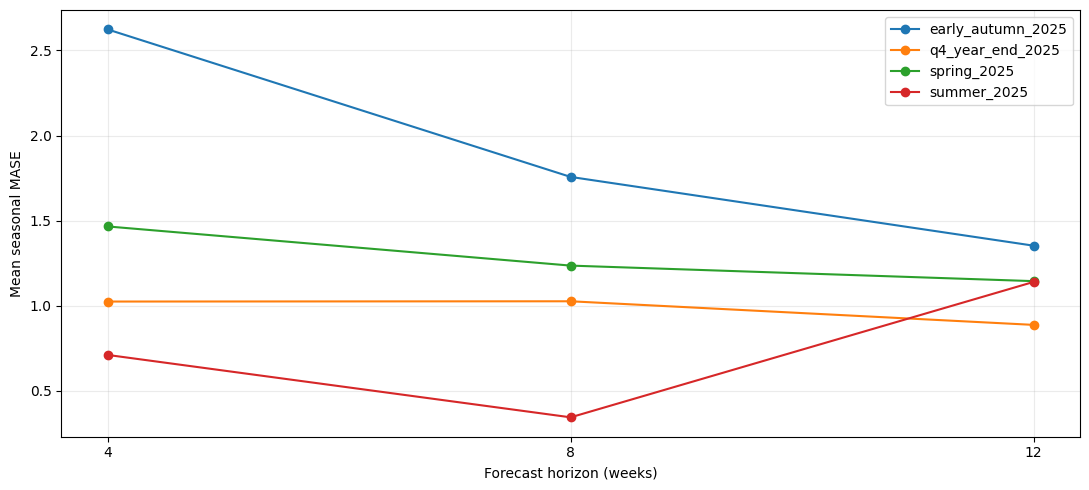

In [11]:
fig,ax=plt.subplots(figsize=(11,5))
for label,g in scenario_summary.groupby('outer_origin_label',sort=False):
    ax.plot(g.sort_values('horizon_weeks')['horizon_weeks'],g.sort_values('horizon_weeks')['MASE'],marker='o',label=label)
ax.set_xlabel('Forecast horizon (weeks)')
ax.set_ylabel('Mean seasonal MASE')
ax.set_xticks(HORIZONS)
ax.legend()
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/'model_4_mase_by_origin_horizon.png',dpi=180)
plt.show()

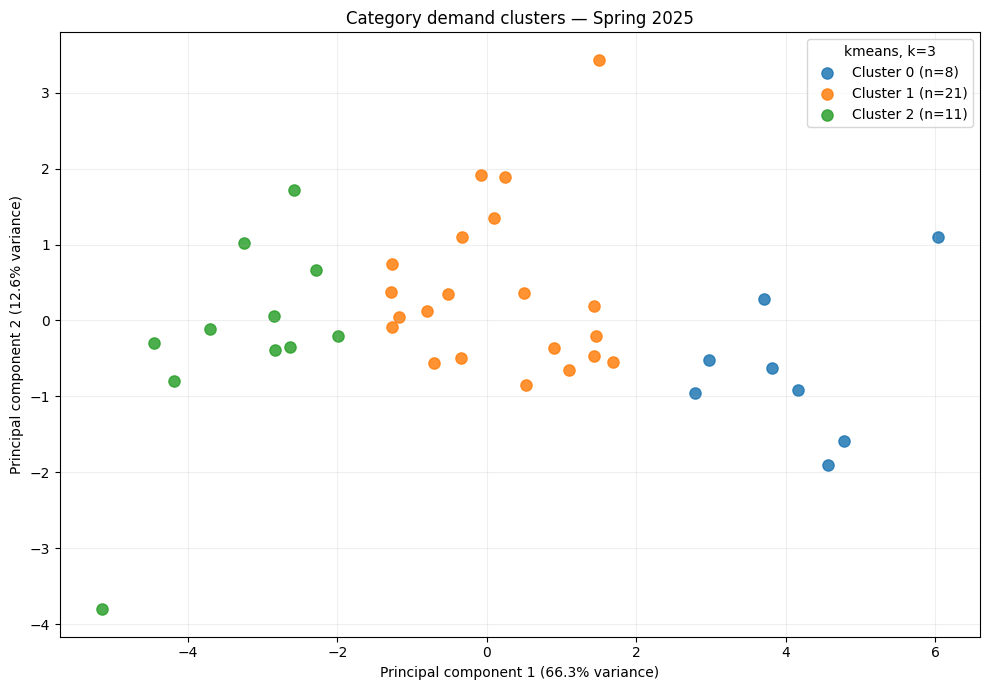

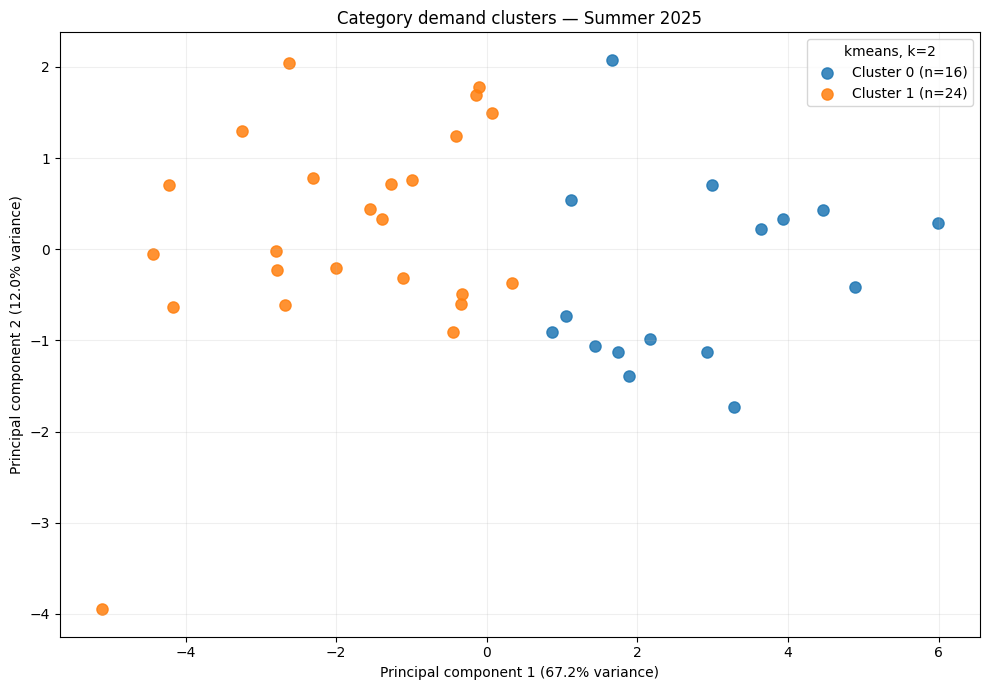

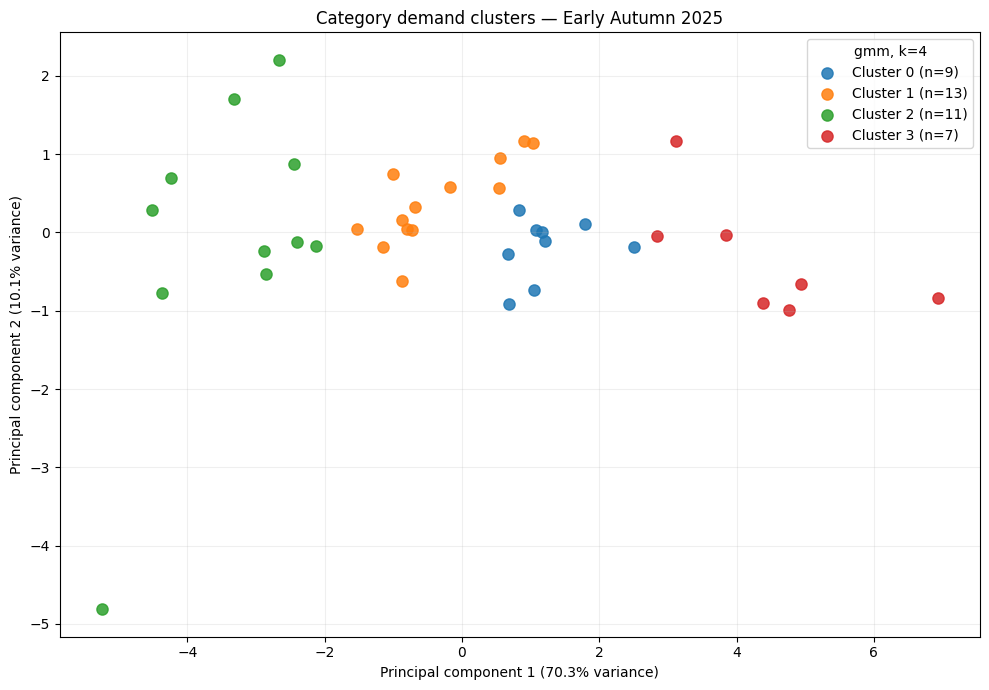

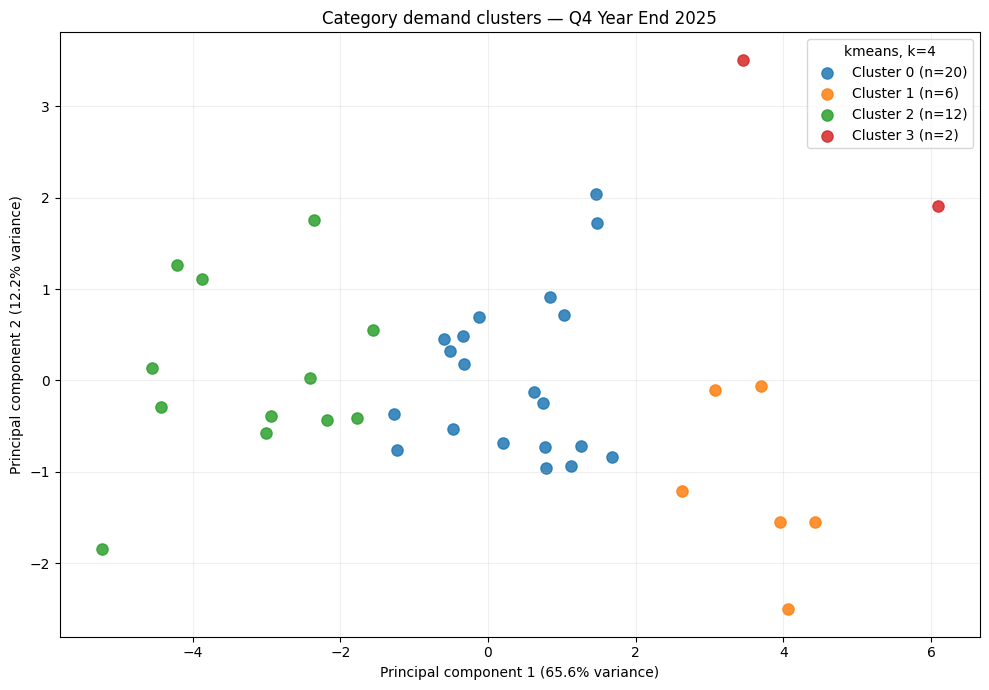

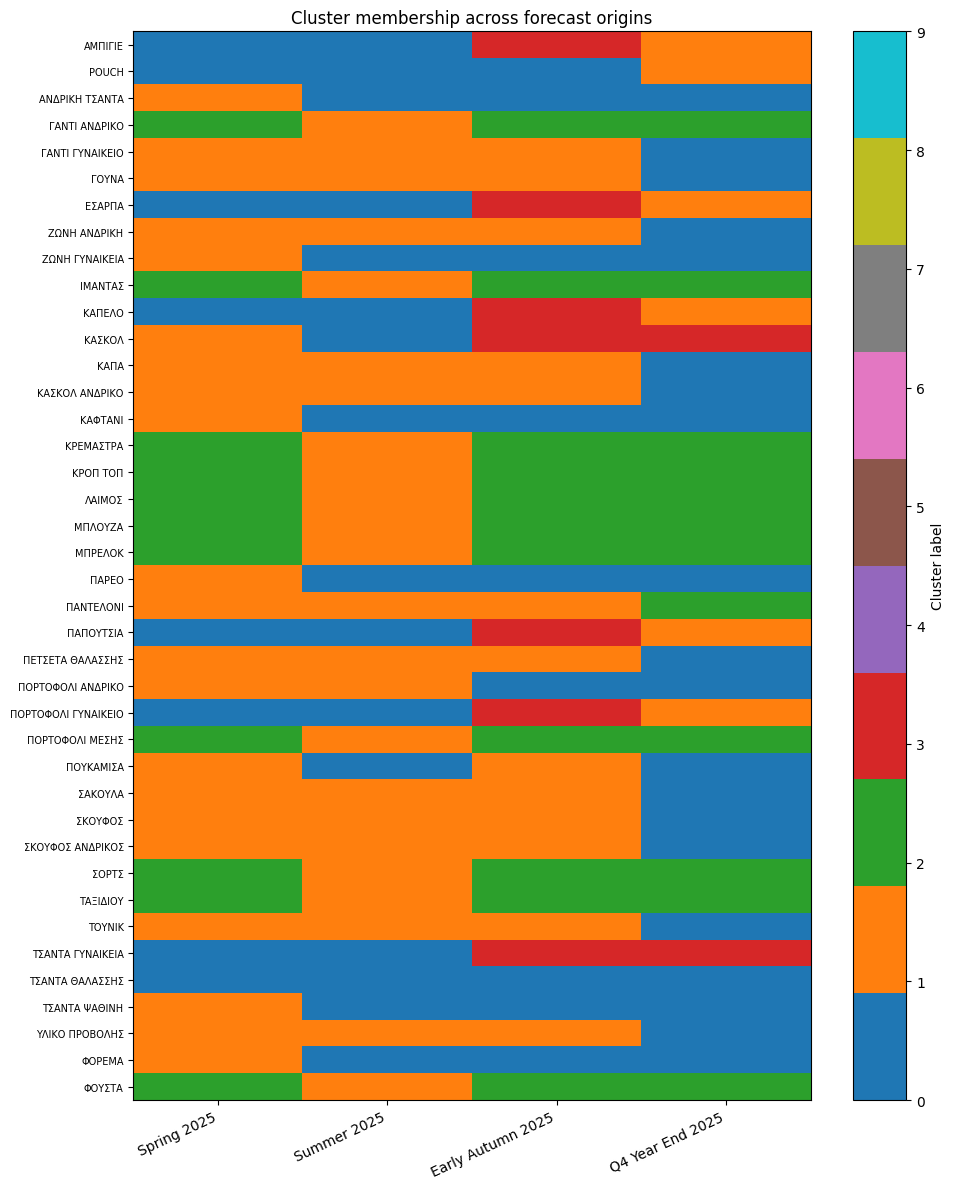

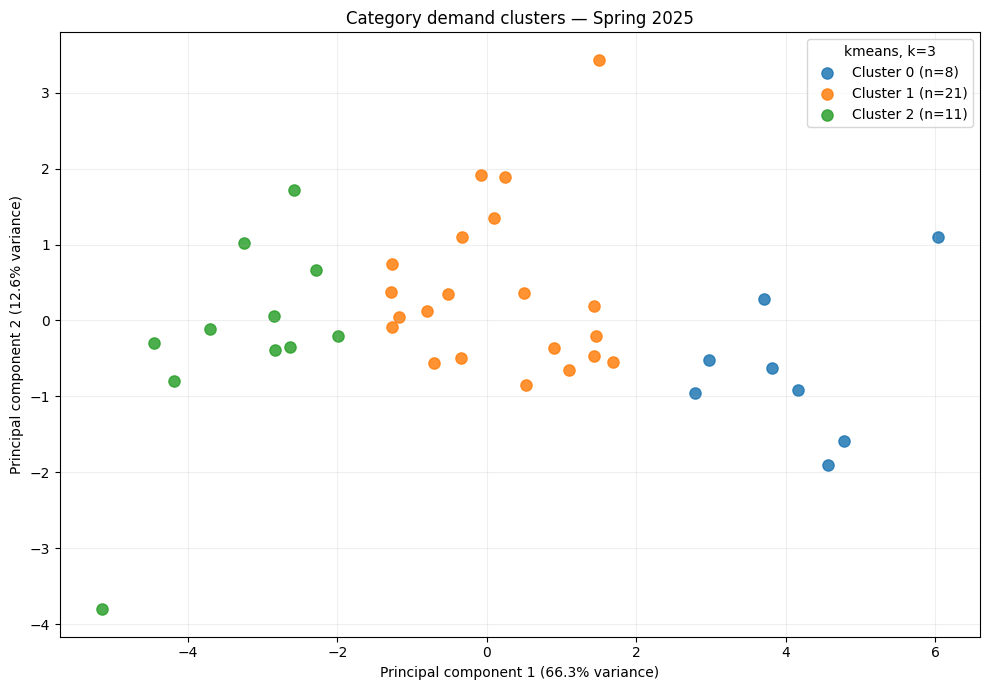

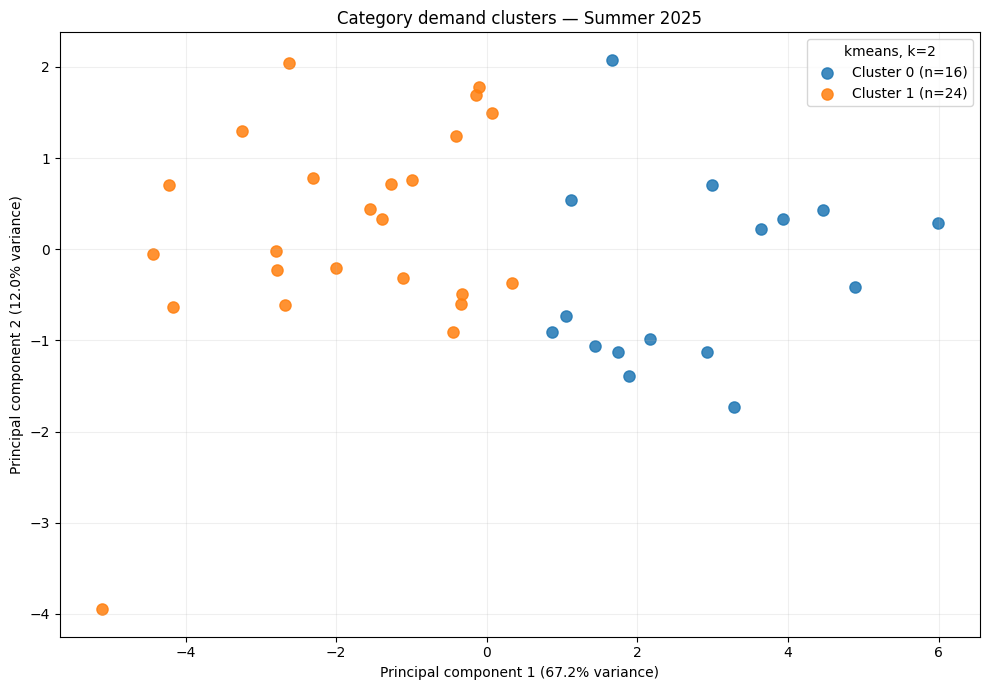

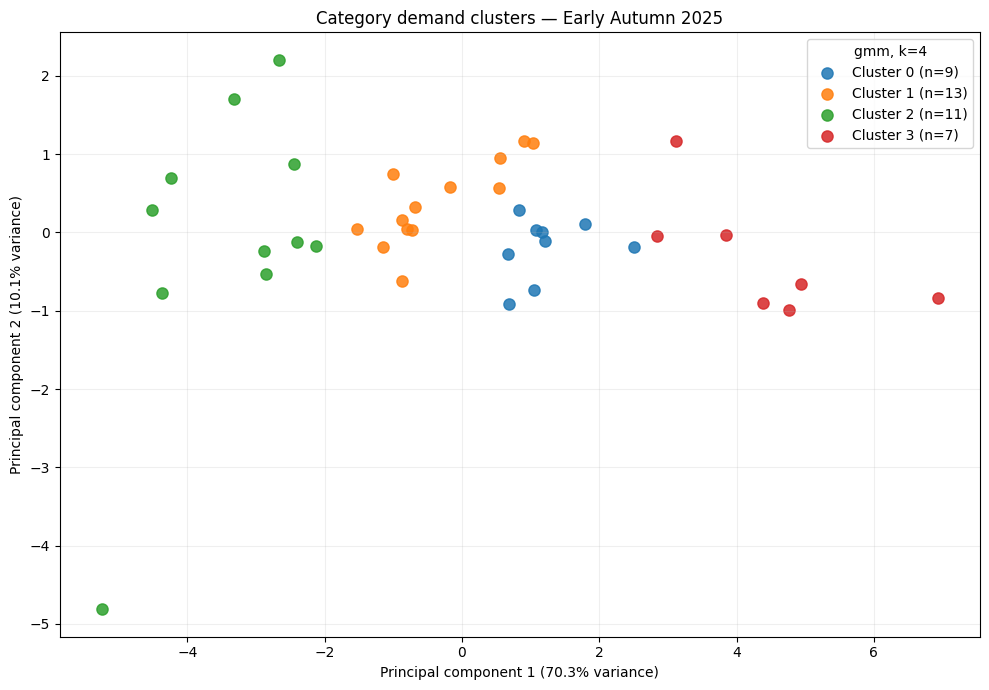

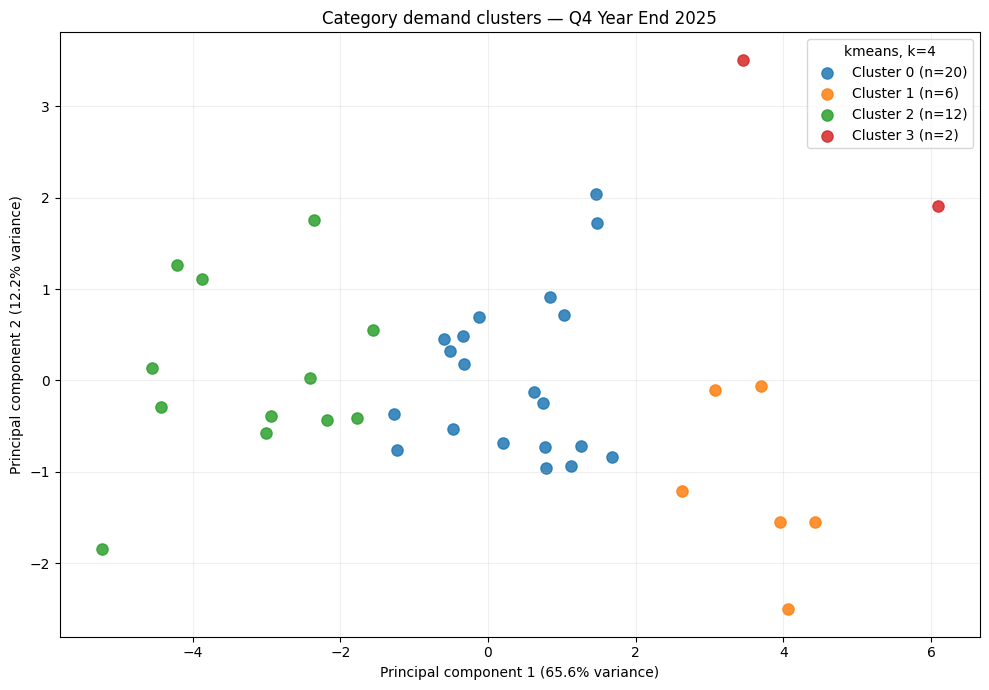

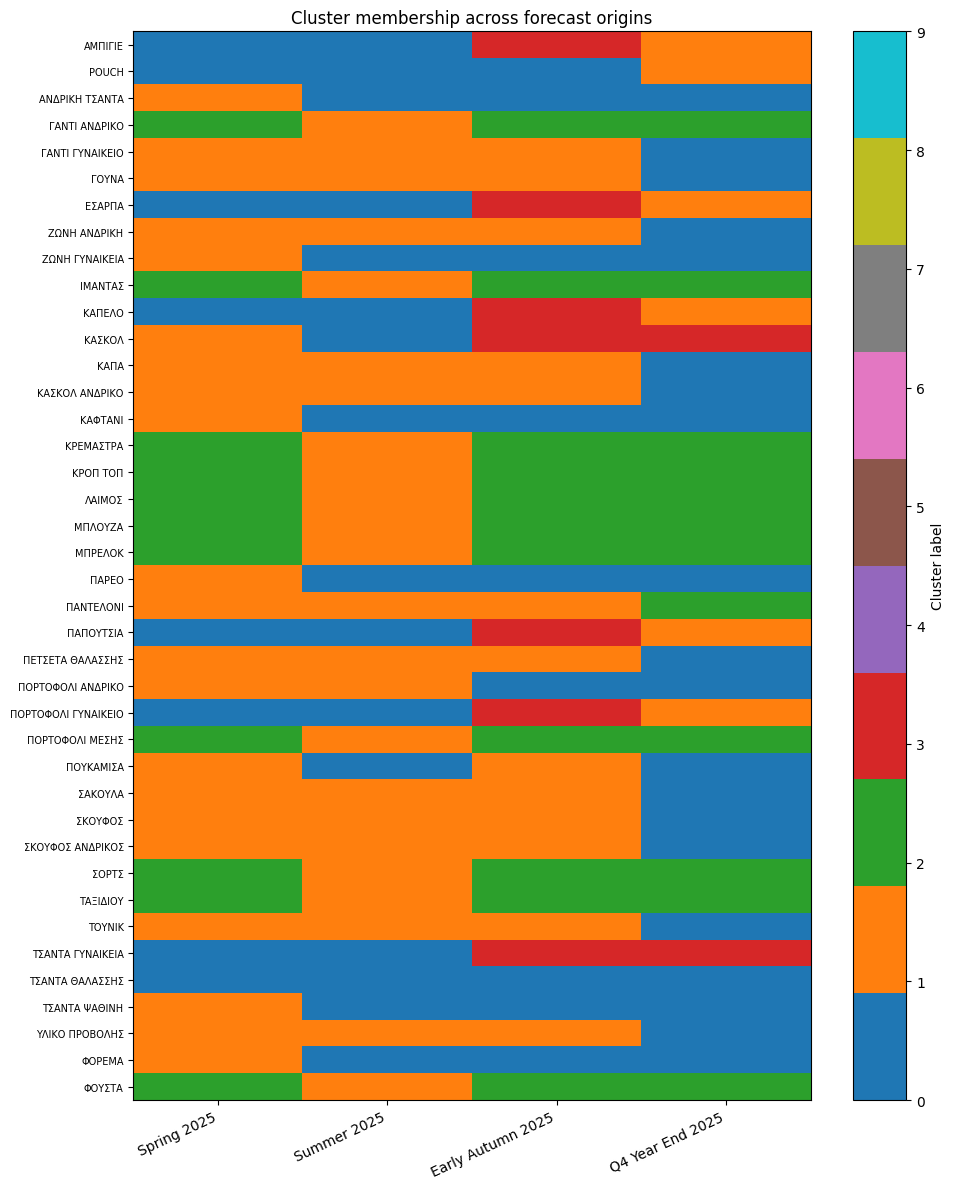

In [12]:
from sklearn.decomposition import PCA

for origin_label, origin_str in ORIGINS.items():
    origin = pd.Timestamp(origin_str)
    train = panel.loc[panel[DATE] < origin]
    config_info = selected_df.loc[selected_df['outer_origin_label'] == origin_label].iloc[0]
    config = {'algorithm':config_info['algorithm'],'k':int(config_info['k'])}
    prof, quality = assign_clusters(train, config)
    x = prof[PROFILE_COLS].copy()
    for c in LOG_COLS:
        x[c] = np.sign(x[c]) * np.log1p(np.abs(x[c]))
    z = StandardScaler().fit_transform(x)
    coords = PCA(n_components=2).fit_transform(z)
    pca = PCA(n_components=2).fit(z)
    fig, ax = plt.subplots(figsize=(10, 7))
    for cluster in sorted(prof['cluster'].unique()):
        mask = prof['cluster'].to_numpy() == cluster
        ax.scatter(coords[mask,0],coords[mask,1],s=65,alpha=.85,label=f'Cluster {cluster} (n={mask.sum()})')
    ax.set_xlabel(f'Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
    ax.set_ylabel(f'Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
    ax.set_title(f'Category demand clusters — {origin_label.replace("_", " ").title()}')
    ax.legend(title=f'{config["algorithm"]}, k={config["k"]}')
    ax.grid(alpha=.2)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f'model_4_clusters_{origin_label}.png',dpi=220,bbox_inches='tight')
    plt.show()

membership = profiles_df.pivot(index=CATEGORY,columns='outer_origin_label',values='cluster')
membership = membership.reindex(columns=list(ORIGINS))
fig, ax = plt.subplots(figsize=(10, 12))
im = ax.imshow(membership.to_numpy(),aspect='auto',interpolation='nearest',cmap='tab10',vmin=0,vmax=9)
ax.set_xticks(np.arange(len(membership.columns)),[x.replace('_',' ').title() for x in membership.columns],rotation=25,ha='right')
ax.set_yticks(np.arange(len(membership.index)),membership.index,fontsize=7)
ax.set_title('Cluster membership across forecast origins')
fig.colorbar(im,ax=ax,label='Cluster label')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'model_4_cluster_membership.png',dpi=220,bbox_inches='tight')
plt.show()


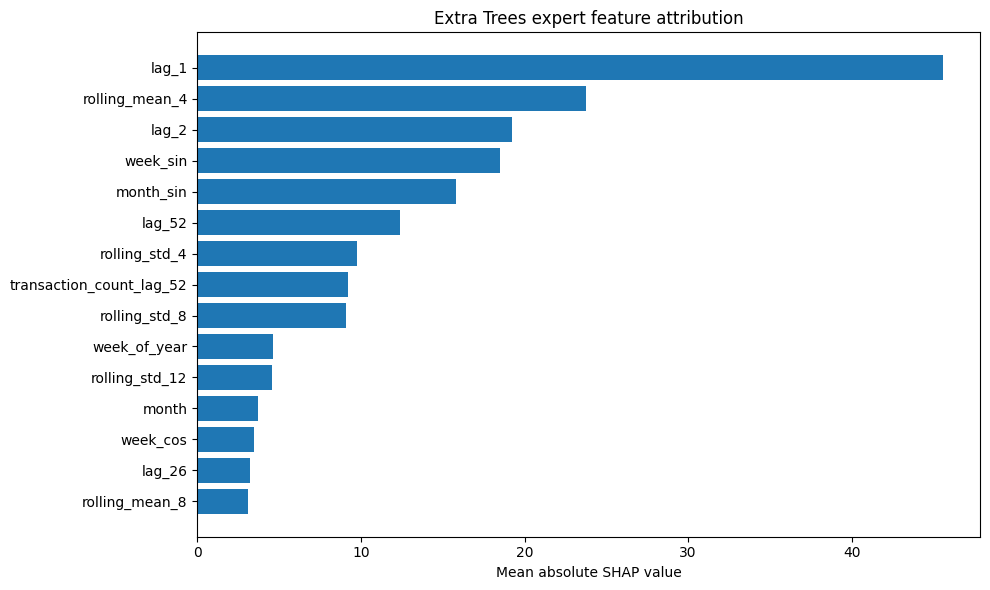

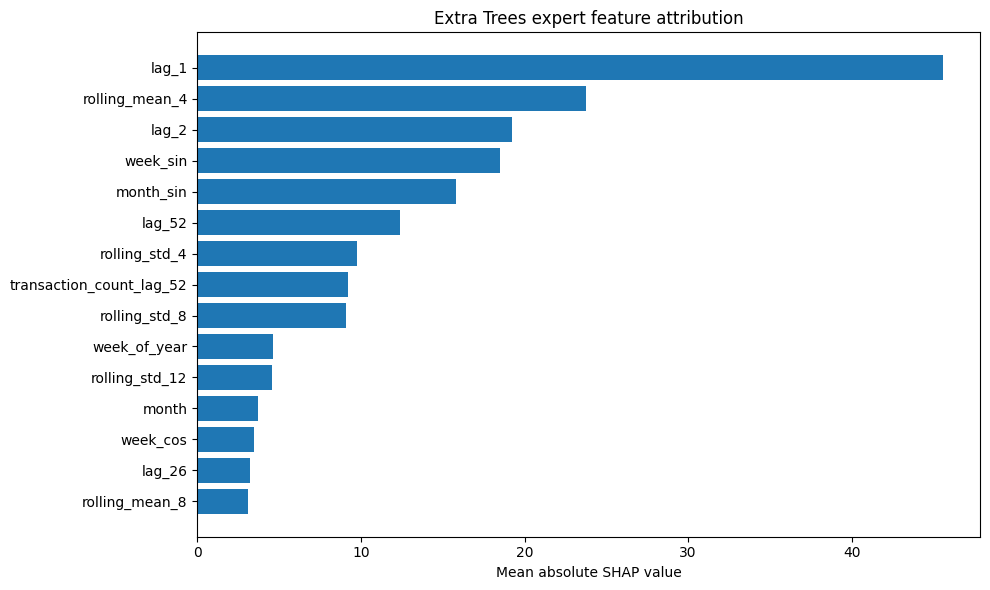

In [13]:
if shap_models:
    import shap
    explanations=[]
    for origin_label,cluster,model,train,cats in shap_models:
        sup=supervised(train,cats)
        sample=sup[FEATURES].sample(min(150,len(sup)),random_state=SEED)
        explainer=shap.TreeExplainer(model)
        values=explainer.shap_values(sample)
        importance=pd.DataFrame({'feature':FEATURES,'mean_abs_shap':np.abs(values).mean(axis=0)})
        importance['outer_origin_label']=origin_label
        importance['cluster']=cluster
        explanations.append(importance)
    shap_df=pd.concat(explanations,ignore_index=True)
    shap_df.to_csv(OUTPUT_DIR/'model_4_tree_expert_shap.csv',index=False)
    summary=shap_df.groupby('feature',as_index=False)['mean_abs_shap'].mean().nlargest(15,'mean_abs_shap').sort_values('mean_abs_shap')
    fig,ax=plt.subplots(figsize=(10,6))
    ax.barh(summary['feature'],summary['mean_abs_shap'])
    ax.set_xlabel('Mean absolute SHAP value')
    ax.set_title('Extra Trees expert feature attribution')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/'model_4_tree_expert_shap.png',dpi=180)
    plt.show()
else:
    print('No Extra Trees expert was selected for the 12-week outer forecasts. SHAP is not applicable to the selected statistical experts.')